## Bank Marketing Subscription Prediction Using Machine Learning

**Banks conduct marketing campaigns through phone calls to convince customers to subscribe to term deposits. However, contacting every customer is time-consuming and costly.**

**The objective of this project is to build a Machine Learning model that predicts whether a customer will subscribe to a term deposit (Yes/No), helping banks identify potential customers and improve marketing campaign efficiency.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

"""
OBJECTIVE:
Predict whether a bank customer will subscribe to a term deposit (Yes / No).

DATASET:
- Bank Marketing Dataset
- 45,211 Records
- Target Column: y (Yes / No)

WORKFLOW:
1. Data Loading and Understanding
2. Data Cleaning and Preprocessing
3. Exploratory Data Analysis (EDA)
4. Outlier Detection and Handling
5. Feature Engineering
6. Categorical Encoding (One-Hot Encoding)
7. Correlation Analysis
8. Feature and Target Selection
9. Train-Test Split (80:20)
10. Random Forest Model Training
11. XGBoost Model Training
12. Model Evaluation (Accuracy, Precision, Recall, F1-Score)
13. Confusion Matrix Analysis
14. ROC Curve and AUC Analysis
15. Final Model Selection (XGBoost)
16. New Customer Prediction
17. Subscription Probability Prediction

FINAL MODEL: XGBoost Classifier

PERFORMANCE:
- Accuracy: 91.56%
- Precision (Yes): 62%
- Recall (Yes): 45%
- F1-Score (Yes): 52%
- ROC-AUC: 93.08%

MODEL COMPARISON:
- Random Forest Accuracy: 91.25%
- XGBoost Accuracy: 91.56%

BUSINESS VALUE:
Helps banks identify potential customers,
improve targeted marketing campaigns,
and reduce unnecessary marketing efforts.
"""

In [2]:
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix


In [3]:
df = pd.read_csv("bank-full.csv", sep=";")

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
df.tail()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [6]:
df.shape

(45211, 17)

In [7]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')

In [8]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [9]:
df.duplicated().sum()

0

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [11]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [12]:
df['y'].value_counts()

y
no     39922
yes     5289
Name: count, dtype: int64

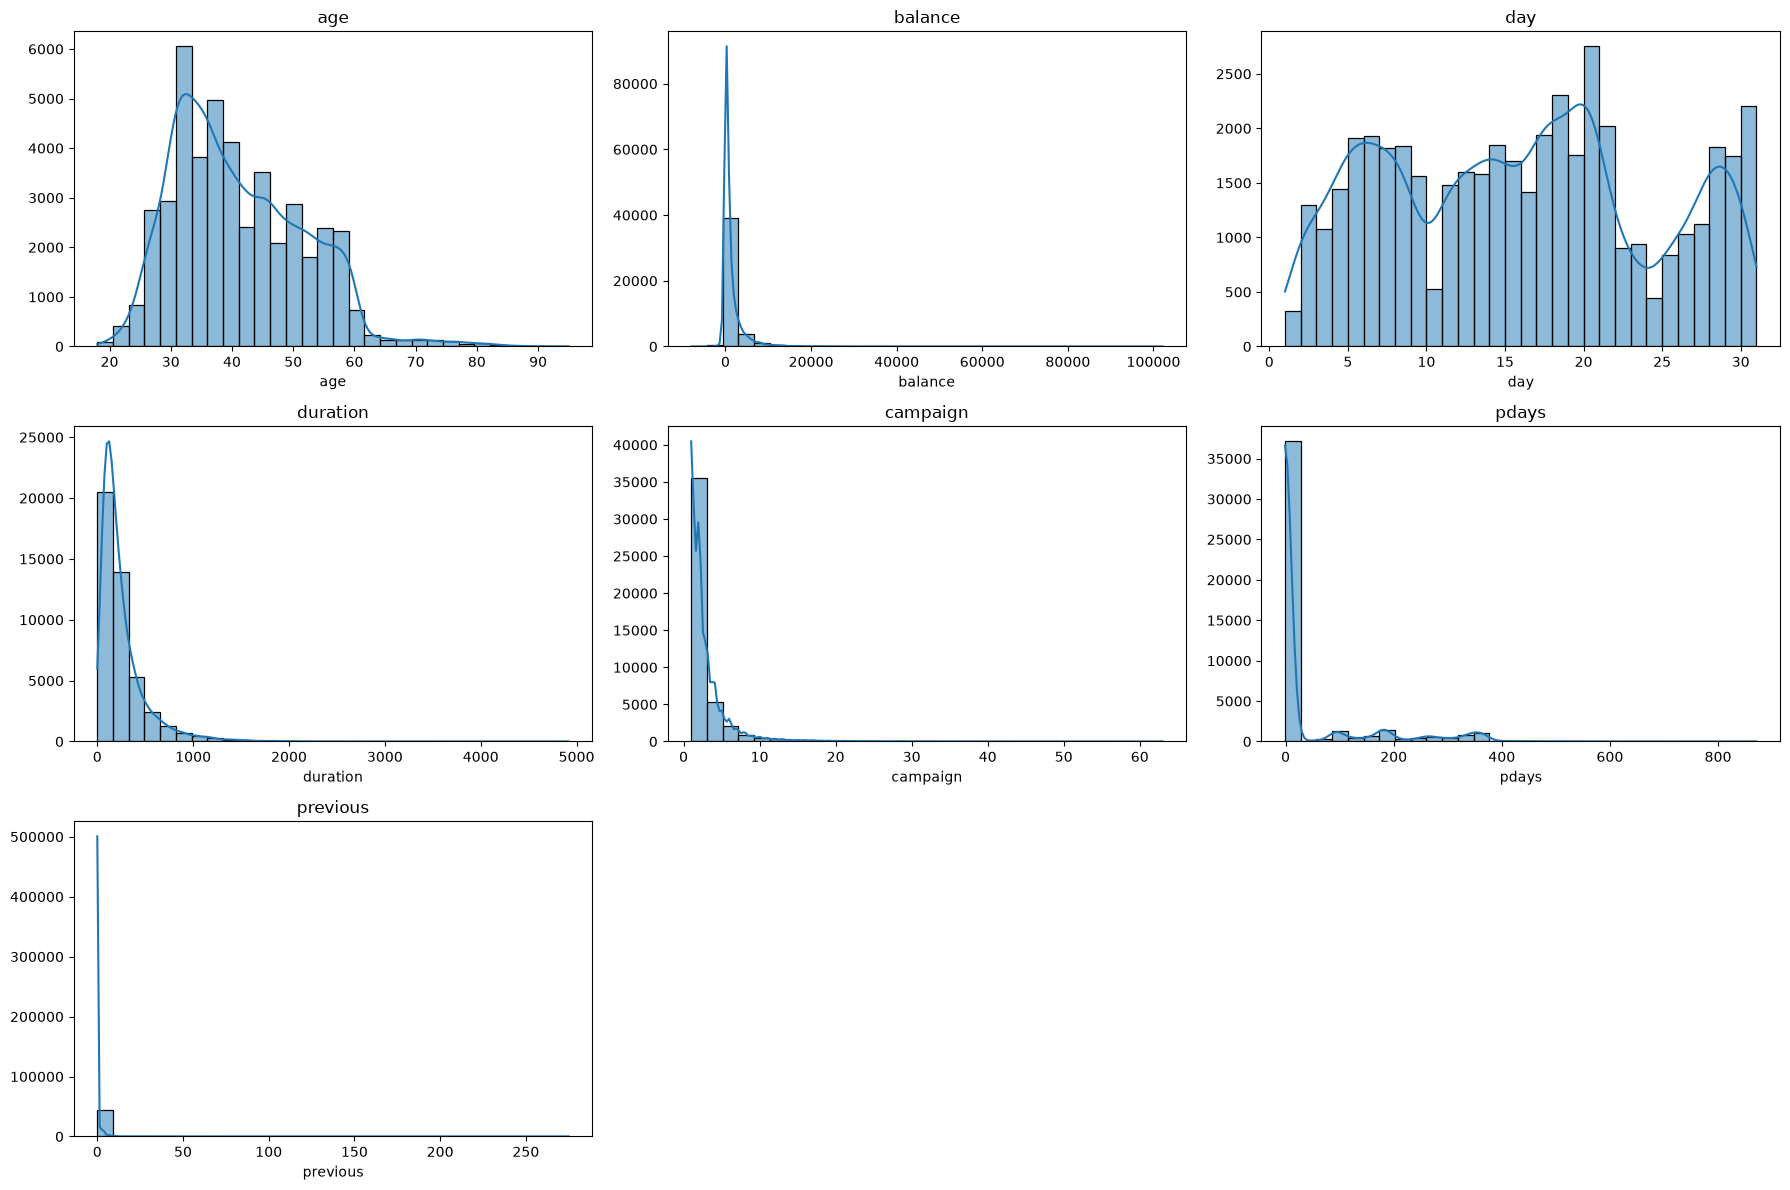

In [13]:
numeric_cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(18, 12))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(col)
    plt.ylabel('')

plt.tight_layout()
plt.show()

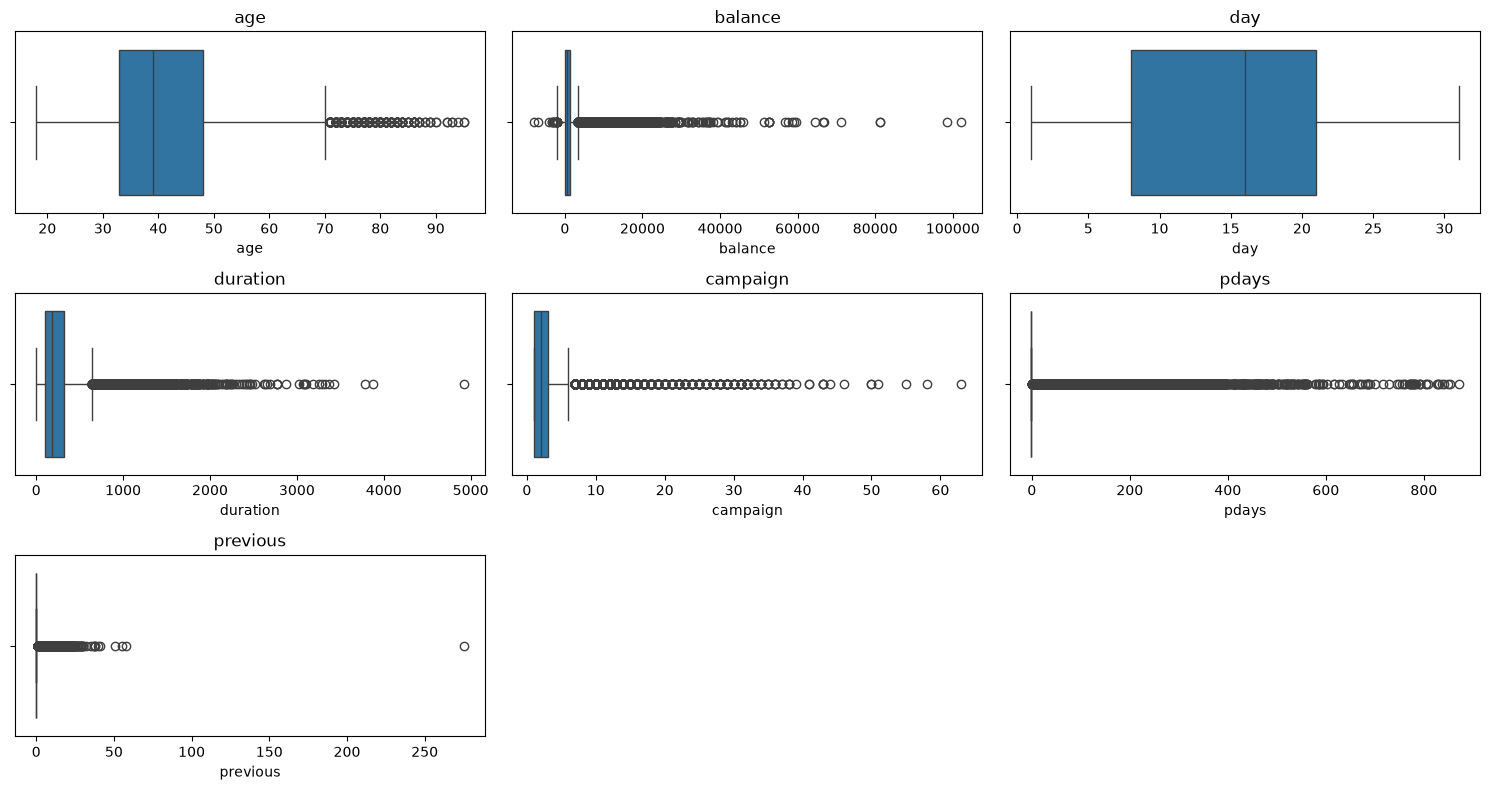

In [14]:
plt.figure(figsize=(15, 8))
numeric_cols = df.select_dtypes(include=['number']).columns

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [15]:
num_cols = df.select_dtypes(include=np.number)

z_scores = np.abs(stats.zscore(df[numeric_cols]))
threshold = 3
df_clean = df[(z_scores < threshold).all(axis=1)]

In [16]:
df_clean.shape

(40209, 17)

In [17]:
df_clean[["age", "balance", "duration", "campaign",
    "pdays", "previous"]].describe()

,age,balance,duration,campaign,pdays,previous
count,40209.000000,40209.000000,40209.000000,40209.000000,40209.000000,40209.000000
mean,40.659728,1083.466189,235.794723,2.464324,25.184312,0.352632
std,10.086648,1722.823814,190.408412,1.951391,71.762763,1.056890
min,18.000000,-6847.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,66.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,430.000000,178.000000,2.000000,-1.000000,0.000000
75%,48.000000,1345.000000,306.000000,3.000000,-1.000000,0.000000
max,72.000000,10483.000000,1030.000000,12.000000,340.000000,7.000000


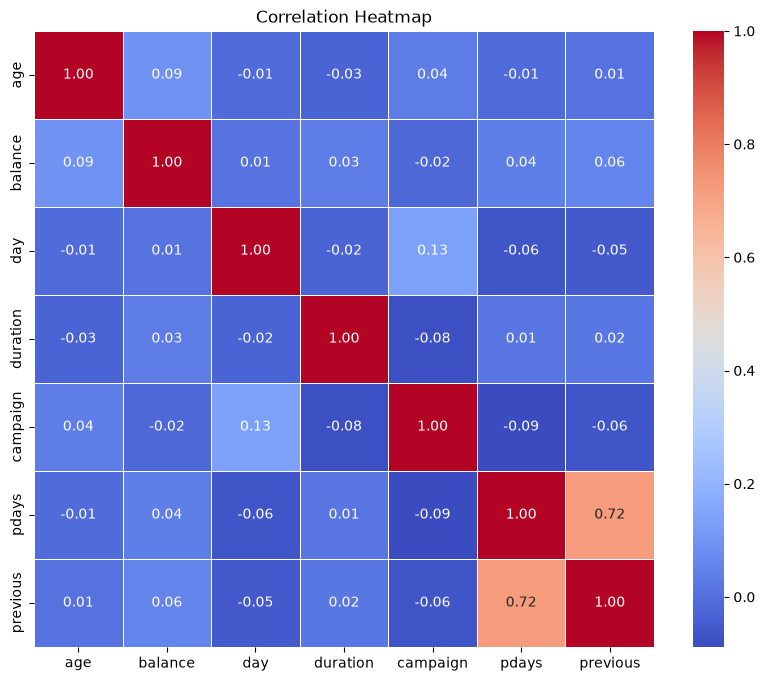

In [18]:
plt.figure(figsize=(10, 8))

correlation_matrix = df_clean.select_dtypes(include=['float64', 'int64']).corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

In [19]:

cat_cols = df_clean.select_dtypes(include="object").columns.drop("y")

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = ohe.fit_transform(df_clean[cat_cols])

encoded_df = pd.DataFrame(
    encoded, 
    columns=ohe.get_feature_names_out(cat_cols), 
    index=df_clean.index
)

df_clean = pd.concat([df_clean.drop(columns=cat_cols), encoded_df], axis=1)

In [20]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df_clean["y"] = le.fit_transform(df_clean["y"])

<Axes: xlabel='y', ylabel='count'>

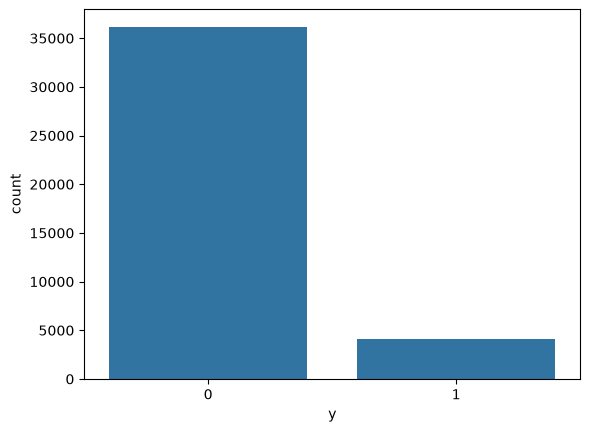

In [21]:
sns.countplot(x= 'y', data= df_clean)

In [22]:
df_clean['y'].value_counts()

y
0    36155
1     4054
Name: count, dtype: int64

In [23]:
X= df_clean.drop('y', axis= 1)

In [24]:
X

,age,balance,day,duration,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,261,1,-1,0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,44,29,5,151,1,-1,0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,33,2,5,76,1,-1,0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,47,1506,5,92,1,-1,0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,33,1,5,198,1,-1,0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45203,23,113,17,266,1,-1,0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
45205,25,505,17,386,2,-1,0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
45206,51,825,17,977,3,-1,0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
45207,71,1729,17,456,2,-1,0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [25]:
y= df_clean['y']

In [26]:
y

0        0
1        0
2        0
3        0
4        0
        ..
45203    1
45205    1
45206    1
45207    1
45209    0
Name: y, Length: 40209, dtype: int64

In [27]:
from sklearn.model_selection import train_test_split

In [28]:
X_train, X_test, y_train, y_test = train_test_split (X,y, test_size=0.20, random_state=42)

In [29]:
rf = RandomForestClassifier()

In [30]:
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [31]:
y_pred = rf.predict(X_test)

In [32]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 0.9133300174086049
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      7215
           1       0.66      0.33      0.44       827

    accuracy                           0.91      8042
   macro avg       0.79      0.65      0.70      8042
weighted avg       0.90      0.91      0.90      8042



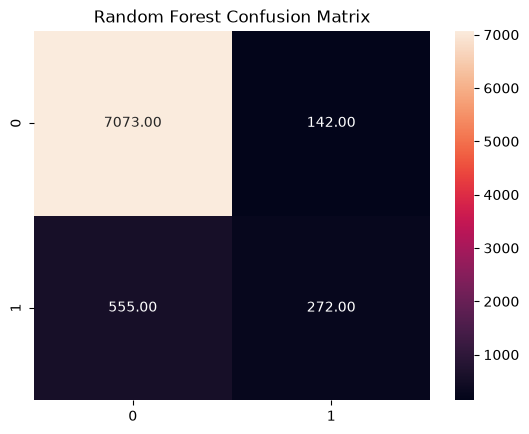

In [33]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='.2f')

plt.title("Random Forest Confusion Matrix")
plt.show()

In [34]:
from xgboost import XGBClassifier

In [35]:
xgb = XGBClassifier()

In [36]:
xgb.fit(X_train, y_train)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [37]:
y_pred_xgb = xgb.predict(X_test)

In [38]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.9155682666003482
              precision    recall  f1-score   support

           0       0.94      0.97      0.95      7215
           1       0.62      0.45      0.52       827

    accuracy                           0.92      8042
   macro avg       0.78      0.71      0.74      8042
weighted avg       0.91      0.92      0.91      8042



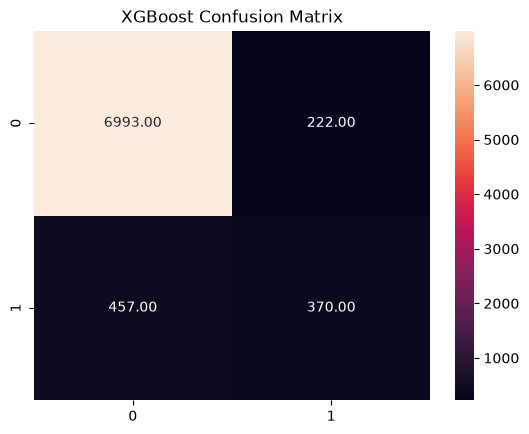

In [39]:
cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='.2f')

plt.title("XGBoost Confusion Matrix")
plt.show()

In [40]:
y_prob = xgb.predict_proba(X_test)[:, 1]

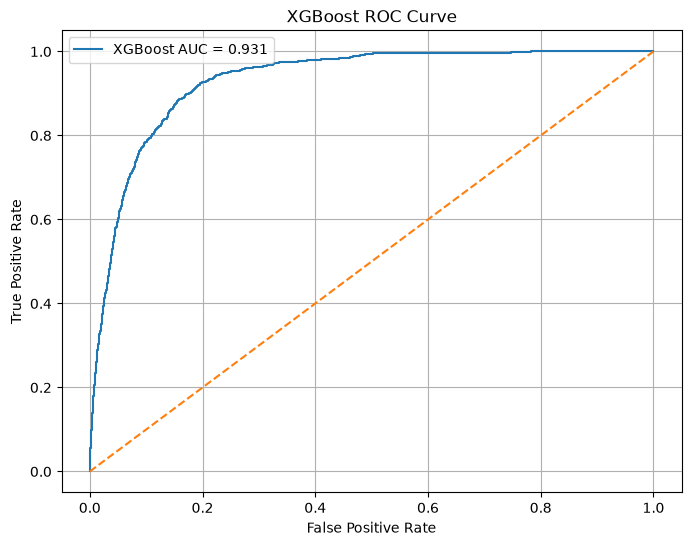

ROC-AUC Score: 0.9307600969027812


In [41]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"XGBoost AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", auc)

In [42]:
new_customer = pd.DataFrame([{
    "age": 35,
    "balance": 2000,
    "day": 15,
    "campaign": 1,
    "pdays": -1,
    "previous": 0
}])

In [43]:
print(X_train.columns.tolist())

['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_divorced', 'marital_married', 'marital_single', 'education_primary', 'education_secondary', 'education_tertiary', 'education_unknown', 'default_no', 'default_yes', 'housing_no', 'housing_yes', 'loan_no', 'loan_yes', 'contact_cellular', 'contact_telephone', 'contact_unknown', 'month_apr', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_failure', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']


In [44]:
new_customer = pd.DataFrame([{
    "age": 30,
    "balance": 5000,
    "day": 10,
    "duration": 1000,
    "campaign": 1,
    "pdays": -1,
    "previous": 0,
    "job": "management",
    "marital": "single",
    "education": "tertiary",
    "default": "no",
    "housing": "no",
    "loan": "no",
    "contact": "cellular",
    "month": "mar",
    "poutcome": "success"
}])

In [45]:
new_cat = ohe.transform(new_customer[cat_cols])

new_cat_df = pd.DataFrame(
    new_cat,
    columns=ohe.get_feature_names_out(cat_cols),
    index=new_customer.index
)

new_num = new_customer.drop(columns=cat_cols)

new_encoded = pd.concat([new_num, new_cat_df], axis=1)

new_encoded = new_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [46]:
prediction = xgb.predict(new_encoded)

probability = xgb.predict_proba(new_encoded)[0][1]

print("Prediction:", "Yes" if prediction[0] == 1 else "No")
print("Subscription Probability:", probability)
print("Probability Percentage:", probability * 100)

Prediction: Yes
Subscription Probability: 0.9698374
Probability Percentage: 96.98374271392822


In [47]:
new_customer = pd.DataFrame([{
    "age": 35,
    "balance": 2000,
    "day": 15,
    "duration": 300,
    "campaign": 5,
    "pdays": -1,
    "previous": 0,
    "job": "blue-collar",
    "marital": "married",
    "education": "secondary",
    "default": "no",
    "housing": "yes",
    "loan": "yes",
    "contact": "unknown",
    "month": "may",
    "poutcome": "unknown"
}])

In [48]:
new_cat = ohe.transform(new_customer[cat_cols])

new_cat_df = pd.DataFrame(
    new_cat,
    columns=ohe.get_feature_names_out(cat_cols),
    index=new_customer.index
)

new_num = new_customer.drop(columns=cat_cols)

new_encoded = pd.concat([new_num, new_cat_df], axis=1)

new_encoded = new_encoded.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [49]:
prediction = xgb.predict(new_encoded)

probability = xgb.predict_proba(new_encoded)[0][1]

print("Prediction:", "Yes" if prediction[0] == 1 else "No")
print("Subscription Probability:", probability)
print("Probability Percentage:", probability * 100)

Prediction: No
Subscription Probability: 0.0005375294
Probability Percentage: 0.053752941312268376
